# 05 · Batch distillation and column efficiency

Small-volume and multipurpose plants - pharmaceuticals, fine chemicals, solvent recovery - distil in batches:
a still is charged, heated, and the distillate collected as the charge grows poorer. This notebook follows
the Rayleigh equation for simple distillation and batch rectification at constant reflux, then turns to
what limits real columns: tray efficiency, packing HETP, and the flooding that sets a column's diameter.

**What you will learn**
- apply the Rayleigh equation and batch rectification
- convert theoretical stages to real trays with efficiencies
- size packed columns by HETP
- estimate the column diameter from flooding

**Before you start:** notebook 03  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import distillation as dist
from engsep import vle
from engsep.vle import y_from_alpha
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Simple (Rayleigh) distillation

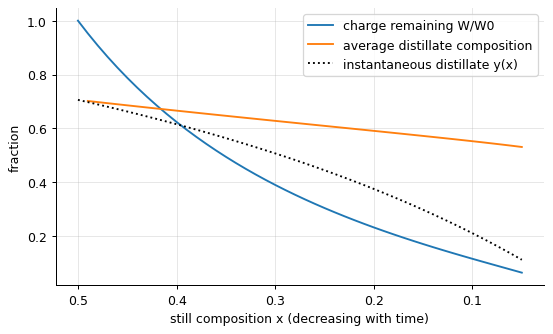

boiling a 50 % charge down to 10 %: 88% distilled, average distillate 0.552 - hardly a separation


In [2]:
alpha = 2.4
y_eq = lambda x: y_from_alpha(x, alpha)
x0 = 0.5
xs = np.linspace(0.5, 0.05, 46)
ray = [dist.rayleigh(y_eq, x0, x_) for x_ in xs]
fig, ax = plt.subplots(); ax.plot(xs, [r["W"] for r in ray], label="charge remaining W/W0"); ax.plot(xs, [r["y_avg"] for r in ray], label="average distillate composition"); ax.plot(xs, [y_eq(x_) for x_ in xs], "k:", label="instantaneous distillate y(x)")
ax.invert_xaxis(); ax.set(xlabel="still composition x (decreasing with time)", ylabel="fraction"); ax.legend(); plt.show()
r = dist.rayleigh(y_eq, x0, 0.1)
print(f"boiling a 50 % charge down to 10 %: {r['D']:.0%} distilled, average distillate {r['y_avg']:.3f} - hardly a separation")

Rayleigh's equation integrates the equilibrium curve as the still is depleted: the distillate is richest at
the start and poorer with every drop, and the accumulated product is a blend. Simple distillation cannot
produce a pure product; it can strip a light impurity, which is what it is used for.

## Batch rectification at constant reflux

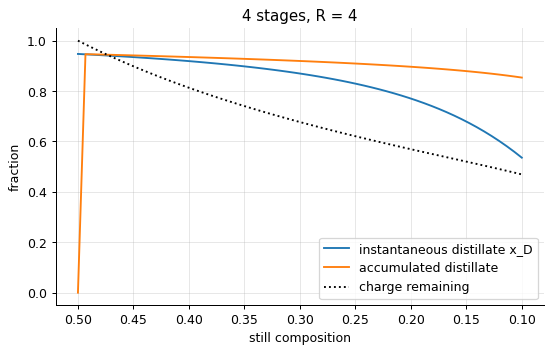

the distillate stays above 80 % until the still reaches x = 0.22, having collected 41% of the charge at an average of 0.902


In [3]:
bcr = dist.batch_constant_reflux(y_eq, x0=0.5, x_final=0.1, R=4.0, N=4)
fig, ax = plt.subplots(); ax.plot(bcr["x_still"], bcr["x_D"], label="instantaneous distillate x_D"); ax.plot(bcr["x_still"], bcr["y_avg"], label="accumulated distillate"); ax.plot(bcr["x_still"], bcr["W"], "k:", label="charge remaining")
ax.invert_xaxis(); ax.set(xlabel="still composition", ylabel="fraction", title="4 stages, R = 4"); ax.legend(); plt.show()
i = np.searchsorted(-bcr["x_D"], -0.8)
print(f"the distillate stays above 80 % until the still reaches x = {bcr['x_still'][i]:.2f}, having collected {bcr['D'][i]:.0%} of the charge at an average of {bcr['y_avg'][i]:.3f}")

A column above the still, run at constant reflux, keeps the distillate pure while the still is rich, then
lets it slide; the operator stops when the distillate falls below specification and the rest is a second
cut. The alternative - raising the reflux continuously to hold the distillate constant - collects less per
hour but keeps every drop on spec. Batch distillation is scheduling as much as separation.

## Tray efficiency: from theoretical stages to real trays

In [4]:
rows = []
for mu in (0.1, 0.3, 1.0, 3.0):
    for a in (1.5, 2.4, 5.0):
        rows.append((mu, a, dist.oconnell_efficiency(a, mu)))
print(pd.DataFrame(rows, columns=["viscosity (mPa s)", "alpha", "O'Connell efficiency"]).round(2).pivot(index="viscosity (mPa s)", columns="alpha", values="O'Connell efficiency").to_string())

alpha               1.5   2.4   5.0
viscosity (mPa s)                  
0.1                0.78  0.70  0.58
0.3                0.60  0.53  0.45
1.0                0.45  0.40  0.33
3.0                0.34  0.30  0.25


O'Connell's correlation captures the two things that hurt tray efficiency: viscous liquids (slow diffusion)
and high relative volatility (the vapour changes composition fast, so a tray's mixing falls behind). Typical
hydrocarbon columns reach 60-80 %; viscous or wide-boiling ones 30-50 %. The real tray count is the
theoretical count divided by this.

## Packed columns: HETP

In [5]:
for packing, hetp in (("25 mm Pall rings", 0.5), ("50 mm Pall rings", 0.75), ("structured (Mellapak 250Y)", 0.35), ("structured (Mellapak 500Y)", 0.2)):
    print(f"{packing:<28}: HETP {hetp} m -> 12 theoretical stages need {dist.packed_height(12, hetp):.1f} m of packing")

25 mm Pall rings            : HETP 0.5 m -> 12 theoretical stages need 6.0 m of packing
50 mm Pall rings            : HETP 0.75 m -> 12 theoretical stages need 9.0 m of packing
structured (Mellapak 250Y)  : HETP 0.35 m -> 12 theoretical stages need 4.2 m of packing
structured (Mellapak 500Y)  : HETP 0.2 m -> 12 theoretical stages need 2.4 m of packing


Packing replaces trays with a continuous surface; its height equivalent to a theoretical plate (HETP) is
measured, not derived - a fraction of a metre for structured packings, which is why they dominate vacuum
and revamp applications where pressure drop and height matter.

## Flooding and column diameter

In [6]:
def flooding_velocity(rho_L, rho_V, sigma, C_sb=0.08):
    # Souders-Brown: u_f = C_sb sqrt((rho_L - rho_V)/rho_V) with a capacity factor C_sb (m/s) including the surface-tension correction
    return C_sb * (sigma / 0.02) ** 0.2 * np.sqrt((rho_L - rho_V) / rho_V)
rho_L, rho_V, sigma = 800.0, 2.8, 0.021                              # benzene-toluene near the top at 1 atm
V = (2.0 + 1) * 45.0 / 3600 * 29.0                                   # vapour (R+1) D in kmol/s times the molar volume at 80 degC (29 m3/kmol)
u_f = flooding_velocity(rho_L, rho_V, sigma)
u = 0.75 * u_f
area = V / u
print(f"flooding velocity {u_f:.2f} m/s; at 75 % of flooding u = {u:.2f} m/s; vapour {V:.3f} m3/s -> area {area:.2f} m2, diameter {np.sqrt(4*area/np.pi):.2f} m")

flooding velocity 1.36 m/s; at 75 % of flooding u = 1.02 m/s; vapour 1.087 m3/s -> area 1.06 m2, diameter 1.16 m


Stages set the height; vapour velocity sets the diameter. Too fast and the vapour carries liquid up the
column (entrainment) or holds it back on the trays (flooding); the Souders-Brown capacity factor gives the
limit, and design runs at 70-80 % of it. A column is two calculations - stages and hydraulics - and this
notebook has now done both.

## Inside the algorithm: the Rayleigh integral

In [7]:
from scipy import integrate
val, _ = integrate.quad(lambda x: 1 / (y_eq(x) - x), 0.1, 0.5)
print("by hand: W/W0 =", np.exp(-val), "; library:", dist.rayleigh(y_eq, 0.5, 0.1)["W"])

by hand: W/W0 = 0.11564469164039978 ; library: 0.11564469164039978


## Exercises
1. A 1000 L charge of 40 mol % methanol in water is distilled in a simple still until the distillate averages 70 %. Use the Wilson equilibrium curve. How much is collected, and what is left in the still?
2. For the batch rectification example, compare constant-reflux operation with constant-distillate-composition operation (raise R to hold x_D = 0.9): which collects more distillate above 0.9 from the same charge, and which takes longer (total vapour boiled)?
3. **Implement it yourself:** compute the O'Connell efficiency yourself and the real tray count for the benzene-toluene column of notebook 03 at three viscosities.